# Segregation Analysis with PySAL

In [1]:
%load_ext watermark
%load_ext autoreload
%autoreload 2

In [2]:
%watermark -v -a "author: eli knaap" -d -u -p segregation,libpysal,geopandas

Author: author: eli knaap

Last updated: 2024-02-11

Python implementation: CPython
Python version       : 3.11.0
IPython version      : 8.21.0

segregation: 2.5
libpysal   : 4.9.2
geopandas  : 0.14.3



Here, we'll use PySAL's `segregation` module to analyze racial segregation in southern california

In [3]:
import geopandas as gpd

## Data Prep

In [4]:
scag = gpd.read_parquet("data/scag_region.parquet")

We need to reproject the data into a more appropriate coordinate system. We can estimate the appropriate 
UTM zone using a method on the geodataframe

In [5]:
scag.estimate_utm_crs()

<Projected CRS: EPSG:32611>
Name: WGS 84 / UTM zone 11N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 120°W and 114°W, northern hemisphere between equator and 84°N, onshore and offshore. Canada - Alberta; British Columbia (BC); Northwest Territories (NWT); Nunavut. Mexico. United States (USA).
- bounds: (-120.0, 0.0, -114.0, 84.0)
Coordinate Operation:
- name: UTM zone 11N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [6]:
scag = scag.to_crs(scag.estimate_utm_crs())

In [9]:
scag.dropna(subset=["p_hispanic_persons"]).explore(
    column="p_hispanic_persons",
    scheme="quantiles",
    cmap="Blues",
    k=8,
    tooltip=["p_hispanic_persons"],
    style_kwds={"stroke": False},
    tiles="Esri.WorldGrayCanvas"
)

some background on [fips codes](https://www.policymap.com/2012/08/tips-on-fips-a-quick-guide-to-geographic-place-codes-part-iii/)

In [10]:
scag["county"] = scag.geoid.str[:5]

In [11]:
scag.county.unique()

array(['06037', '06025', '06059', '06071', '06073', '06065', '06111'],
      dtype=object)

In [12]:
county_names = [
    "Los Angeles",
    "Imperial",
    "Orange",
    "San Bernardino",
    "San Diego",
    "Riverside",
    "Ventura",
]

In [13]:
namer = dict(zip(scag.county.unique(), county_names))

In [14]:
namer

{'06037': 'Los Angeles',
 '06025': 'Imperial',
 '06059': 'Orange',
 '06071': 'San Bernadino',
 '06073': 'San Diego',
 '06065': 'Riverside',
 '06111': 'Ventura'}

Now that we know which county is which, we could just use these codes to divide up the region into pieces. But lets go ahead and replace the codes with their names. It's more to type, but if we want to subset later, we won't have to go look up the codes again

In [15]:
scag["county"] = scag.county.replace(to_replace=namer)

In [16]:
scag.county

0       Los Angeles
1       Los Angeles
2       Los Angeles
3       Los Angeles
4       Los Angeles
           ...     
4575    Los Angeles
4576    Los Angeles
4577        Ventura
4578      Riverside
4579    Los Angeles
Name: county, Length: 4580, dtype: object

In [17]:
coastal = scag[scag.county.isin(["Los Angeles", "Orange", "San Diego", "Ventura"])]

In [18]:
inland = scag[scag.county.isin(["Riverside", "San Bernardino", "Imperial"])]

<Axes: >

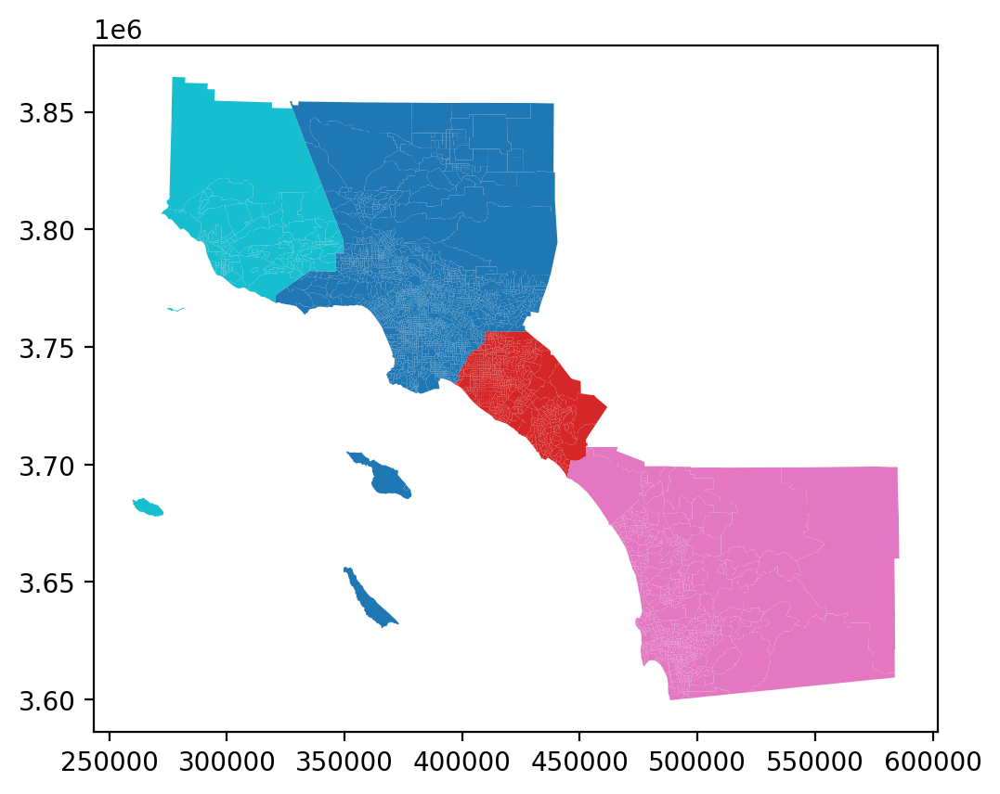

In [19]:
coastal.plot(column="county")

<Axes: >

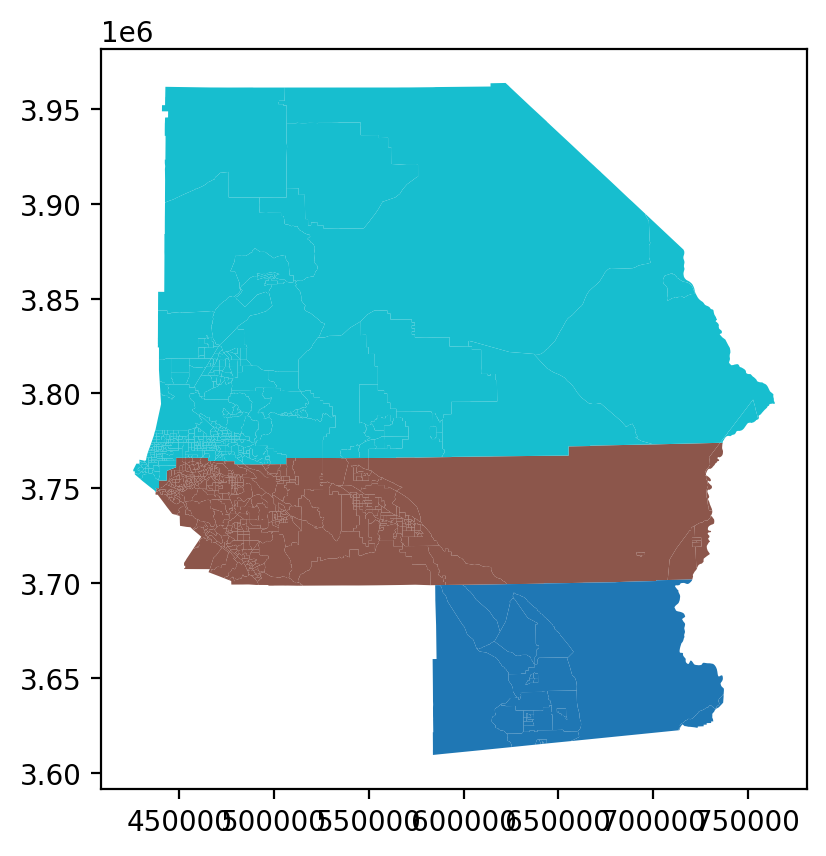

In [20]:
inland.plot(column="county")

In [21]:
pop_groups = [
    "n_asian_persons",
    "n_hispanic_persons",
    "n_nonhisp_black_persons",
    "n_nonhisp_white_persons",
]

In [22]:
scag[pop_groups] = scag[pop_groups].astype(int)
scag["n_total_pop"] = scag["n_total_pop"].astype(int)

## Calculating Segregation Measures

The `segregation` package calculates dozens of segregation indices, each of which captures something different about the ways that population groups interact or remain separated in space. Most of the commonly-used statistics are global or aggregate measures, meaning they summarize the total level of segregation across all units in a study region. 

### Classic (aspatial) Single-Group Indices

Single-group indices measure the partitioning of one population group relative to everyone else. 

In [23]:
from segregation.singlegroup import Dissim, Entropy, Gini

In [24]:
dissim_hisp = Dissim(scag, "n_hispanic_persons", "n_total_pop")
dissim_black = Dissim(scag, "n_nonhisp_black_persons", "n_total_pop")

gini_hisp = Gini(scag, "n_hispanic_persons", "n_total_pop")
gini_black = Gini(scag, "n_nonhisp_black_persons", "n_total_pop")

entropy_hisp = Entropy(scag, "n_hispanic_persons", "n_total_pop")
entropy_black = Entropy(scag, "n_nonhisp_black_persons", "n_total_pop")

/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/segregation/singlegroup/gini.py:54: NumbaExperimentalFeatureWarning: Use of isinstance() detected. This is an experimental feature.
  pi = np.where(ti == 0, 0, pi / ti)
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Each class has a `statistic` attribute that holds the computed value for each segregation measure

In [25]:
dissim_hisp.statistic

0.4820197253710138

In [26]:
dissim_black.statistic

0.5158629911818775

In [27]:
gini_hisp.statistic

0.6368128074464425

In [28]:
gini_black.statistic

0.6881521050448999

In [29]:
entropy_hisp.statistic

0.2499271894539663

In [30]:
entropy_black.statistic

0.2380776417487409

According to the Dissimilarity and Gini indices, the black population in southern California is more segregated than the Latinx/Hispanic population, but the reverse is true according to the Entropy index

#### Batch Computation

To examine several indices at once, `segregation` provides a set of "batch_compute" functions. 

In [31]:
from segregation.batch import batch_compute_singlegroup

In [32]:
scag["n_total_pop"] = scag["n_total_pop"].astype(int)

In [33]:
scag_all_singlegroup = batch_compute_singlegroup(
    scag.dropna(subset=["n_hispanic_persons"]), "n_hispanic_persons", "n_total_pop"
)

  0%|          | 0/27 [00:00<?, ?it/s]

In [34]:
scag_all_singlegroup

,Statistic
Name,
AbsoluteCentralization,0.7852
AbsoluteClustering,0.2024
AbsoluteConcentration,0.6770
Atkinson,0.3410
BiasCorrectedDissim,0.4819
BoundarySpatialDissim,NaN
ConProf,0.4590
CorrelationR,0.3050
Delta,0.8706


In [35]:
from segregation.singlegroup import BoundarySpatialDissim

In [36]:
BoundarySpatialDissim(scag, "n_hispanic_persons", "n_total_pop").statistic

/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There is 1 island with id: 4285.
  warnings.warn(message)
/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/segregation/_base.py:41: UserWarning: There are some islands in the GeoDataFrame.
  warnings.warn("There are some islands in the GeoDataFrame.")
/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 1153 disconnected components.
  warnings.warn(message)
/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  warnings.warn(message)
/Users/knaaptime/mambaf

nan

In [ ]:
scag_all_singlegroup

### Multigroup Indices

Multigroup measures capture the partitioning of several groups simultaneously

In [38]:
from segregation.multigroup import MultiDiversity, MultiGini, MultiInfoTheory

In [44]:
multi_div_coast = MultiDiversity(coastal, pop_groups)
multi_div_inland = MultiGini(inland, pop_groups)

multi_gini_inland = MultiGini(inland, pop_groups)
multi_gini_coast = MultiGini(coastal, pop_groups)


Multgini_inland = MultiGini(inland, pop_groups)

multi_info_coast = MultiInfoTheory(coastal, pop_groups)

multi_info_inland = MultiInfoTheory(inland, pop_groups)

For multigroup diversity:

In [40]:
print(f"coast: {multi_div_coast.statistic}")
print(f"inland: {multi_div_inland.statistic}")

coast: 1.1809358619327062
inland: 1.0759374739082923


In [45]:
print(f"coast: {multi_gini_coast.statistic}")
print(f"inland: {multi_gini_inland.statistic}")

coast: 0.6722979422987735
inland: 0.5396738741760281


for multigroup information theory:

In [41]:
print(f"coast: {multi_info_coast.statistic}")
print(f"inland: {multi_info_inland.statistic}")

coast: 0.29595481043925786
inland: 0.17469309549624326


In [ ]:
print(f"coast: {multi_info_coast.statistic}")
print(f"inland: {multi_info_inland.statistic}")

Regardless which index is used, multigroup segregation is higher in the coastal region than the inland one

#### Batch Computation

Again, the measures can be "batch computed"

In [46]:
from segregation.batch import batch_compute_multigroup

In [47]:
scag_all_multigroup = batch_compute_multigroup(scag, groups=pop_groups)

In [48]:
scag_all_multigroup

,Statistic
Name,
GlobalDistortion,125.1609
MultiDissim,0.4955
MultiDivergence,0.3218
MultiDiversity,1.1650
MultiGini,0.6538
MultiInfoTheory,0.2762
MultiNormExposure,0.2889
MultiRelativeDiversity,0.2799
MultiSquaredCoefVar,0.2351


### Spatial Segregation Indices



Every index in the `segregation` package can leverage spatial relationships in its computation. Some segregation indices include a spatially-explicit formulation, e.g. the [spatial dissimilarity index](https://journals.sagepub.com/doi/abs/10.1080/00420989320080551?). Others can be generalized into spatial versions using the logic of [Reardon et al](https://link.springer.com/article/10.1353/dem.0.0019), in which case we adopt the notion of ['egohoods'](https://escholarship.org/uc/item/71m5522z)

In [51]:
from libpysal.graph import Graph

In [52]:
from segregation.singlegroup import SpatialDissim

In [53]:
# segregation still expects libpysal's older W class, so each Graph is converted with to_W()
w_queen = Graph.build_contiguity(scag, rook=False).to_W()
w_dist = Graph.build_distance_band(scag.centroid, threshold=2500).to_W()

/var/folders/79/cknfb1sx2pv16rztkpg6wzlw0000gn/T/ipykernel_55538/2074120131.py:1: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w_queen = weights.Queen.from_dataframe(scag)
/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There is 1 island with id: 4285.
  warnings.warn(message)
/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 421 disconnected components.
 There are 362 islands with ids: 157, 159, 162, 163, 164, 165, 209, 243, 245, 276, 344, 405, 415, 437, 447, 457, 481, 482, 484, 489, 490, 492, 518, 774, 873, 907, 908, 963, 970, 971, 972, 973, 1017, 1053, 1055, 1070, 1105, 1118, 11

#### Single Group

In [54]:
dissim = Dissim(scag, "n_hispanic_persons", "n_total_pop")

In [57]:
dissim.statistic

0.4820197253710138

In [55]:
# spatial
spatdissim = SpatialDissim(scag, "n_hispanic_persons", "n_total_pop")

/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/segregation/singlegroup/spatial_dissim.py:48: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w_object = Queen.from_dataframe(data)
/Users/knaaptime/mambaforge/envs/workshop-pysal-wrsa24/lib/python3.11/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There is 1 island with id: 4285.
  warnings.warn(message)


In [58]:
spatdissim.statistic

0.35351598194379474

In [59]:
# spatially-explicit index (using queen neighborhoods)

dissim_queen = SpatialDissim(scag, "n_hispanic_persons", "n_total_pop", w=w_queen)

In [60]:
dissim_queen.statistic

0.35351598194379474

In [61]:
# spatially-explicit index using distance-based neighborhoods of 2500m)
# exeryone inside the distance-band has the same interaction potential

dissim_dist = SpatialDissim(scag, "n_hispanic_persons", "n_total_pop", w=w_dist)

In [62]:
dissim_dist.statistic

0.32528787128722025

In [68]:
# spatially-implicit Dissimilarity index
# the interaction potential among people inside the distance-band is weighted by proximity

dissim_implicit_linear = Dissim(
    scag, "n_hispanic_persons", "n_total_pop", distance=2500
)

In [66]:
dissim = Dissim(scag, "n_hispanic_persons", "n_total_pop")

In [67]:
dissim.statistic

0.4820197253710138

In [69]:
dissim_implicit_linear.statistic

0.419934659874957

In [64]:
dissim_implicit_gaussian = Dissim(
    scag, "n_hispanic_persons", "n_total_pop", distance=2500, function="gaussian"
)

In [65]:
dissim_implicit_gaussian.statistic

0.4088864028124059

In [ ]:
# spatially-implicit Dissimilarity index
dissim_implicit = Dissim(scag, "n_hispanic_persons", "n_total_pop", distance=3000)

In [ ]:
dissim_implicit.statistic

#### Multi Group

In [70]:
spatial_info_queen = MultiInfoTheory(scag, pop_groups, w=w_queen)
spatial_info_dist = MultiInfoTheory(scag, pop_groups, w=w_dist)

In [71]:
info_spatial = MultiInfoTheory(scag, groups=pop_groups, distance=2000)

In [72]:
spatial_info_queen.statistic

0.21447331455751437

In [73]:
spatial_info_dist.statistic

0.2194825382416494

In [74]:
info_spatial.statistic

0.2504788684490104

## Spatial Segregation Dynamics

#### Multiscalar Profile

The multiscalar segregation profile is a way of measuring how global versus local the segregation patterns are in a region. As stylized examples, consider a city where one population groups lives on the eastern half and another group lives on the western half (large-scale/macro segregation) versus a city full of dense apartment buildings, but each building is occupied exclusively by members of a single population group

![](https://knaaptime.com/images/macromicro.jpeg)

In [75]:
from segregation.dynamics import compute_multiscalar_profile

In [76]:
distances = [1500.0, 2500.0, 3500.0, 4500.0, 5500.0]

In [77]:
prof = compute_multiscalar_profile(
    scag, segregation_index=MultiInfoTheory, groups=pop_groups, distances=distances
)

<Axes: xlabel='distance'>

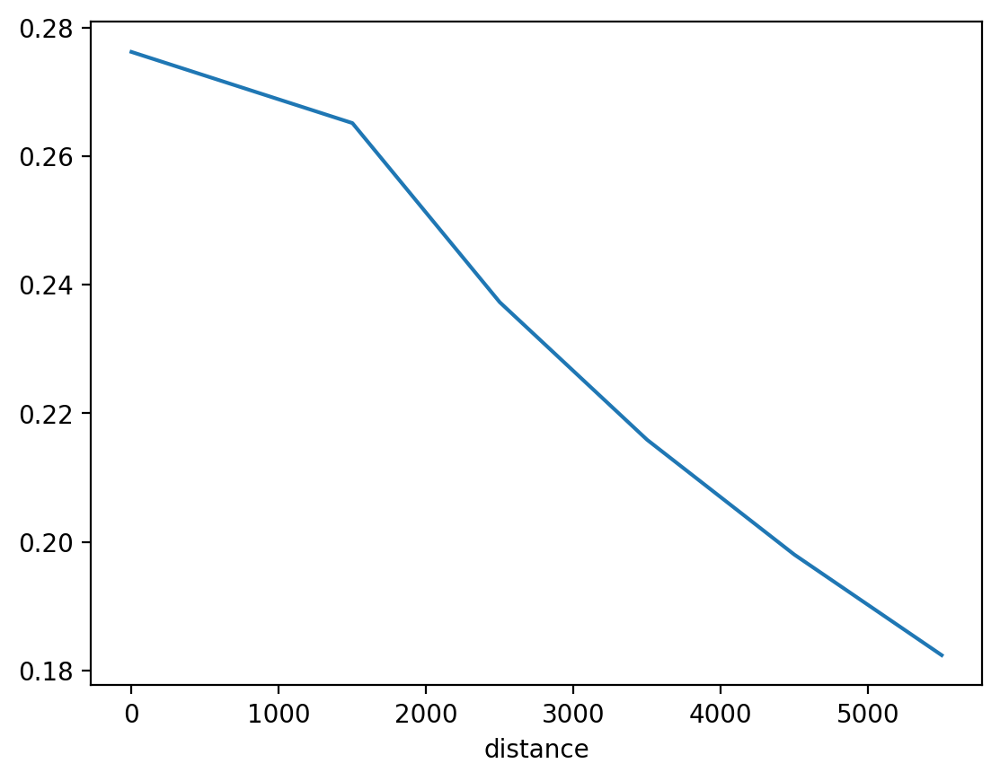

In [78]:
prof.plot()

We can also look at how the segregation profiles differ by region. If we plot them all on the same graph, we can compare the slopes of the lines to see how the shape of segregation differs between places in the southern cal region

In [79]:
coastal_prof = compute_multiscalar_profile(
    coastal, segregation_index=MultiInfoTheory, groups=pop_groups, distances=distances
)
inland_prof = compute_multiscalar_profile(
    inland, segregation_index=MultiInfoTheory, groups=pop_groups, distances=distances
)

In [80]:
import pandas as pd

<Axes: xlabel='distance'>

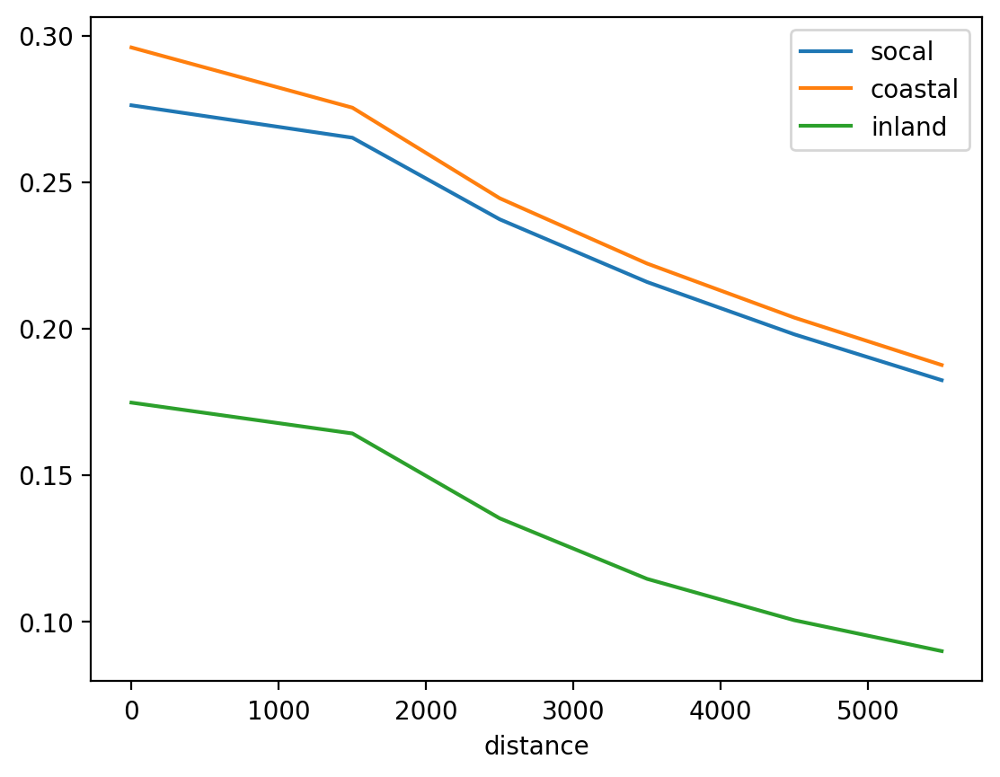

In [81]:
pd.Series(prof, name="socal").plot(legend=True)
pd.Series(coastal_prof, name="coastal").plot(legend=True)
pd.Series(inland_prof, name="inland").plot(legend=True)

## Local Segregation Measures

Unlike global measures, local segregation statistics measure 

In [82]:
from segregation.local import LocalDistortion, MultiLocationQuotient

In [83]:
d = LocalDistortion(scag, groups=pop_groups)

In [85]:
d.data

,distortion,geometry
observation,,
0,46.566720,"POLYGON ((366469.395 3781383.154, 367274.320 3..."
1,40.620287,"POLYGON ((356092.493 3787689.814, 356495.267 3..."
2,44.475757,"POLYGON ((354475.226 3787187.203, 354877.648 3..."
3,48.255995,"POLYGON ((351261.681 3787675.748, 351660.138 3..."
4,464.097765,"POLYGON ((384094.465 3756080.466, 384101.841 3..."
...,...,...
4575,40.297282,"POLYGON ((361824.826 3810425.196, 362123.426 3..."
4576,355.467162,"POLYGON ((388383.463 3752560.240, 388471.148 3..."
4577,66.574166,"POLYGON ((295281.925 3784488.310, 295656.670 3..."


In [86]:
import contextily as ctx

In [87]:
d.data.crs

<Projected CRS: EPSG:32611>
Name: WGS 84 / UTM zone 11N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 120°W and 114°W, northern hemisphere between equator and 84°N, onshore and offshore. Canada - Alberta; British Columbia (BC); Northwest Territories (NWT); Nunavut. Mexico. United States (USA).
- bounds: (-120.0, 0.0, -114.0, 84.0)
Coordinate Operation:
- name: UTM zone 11N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

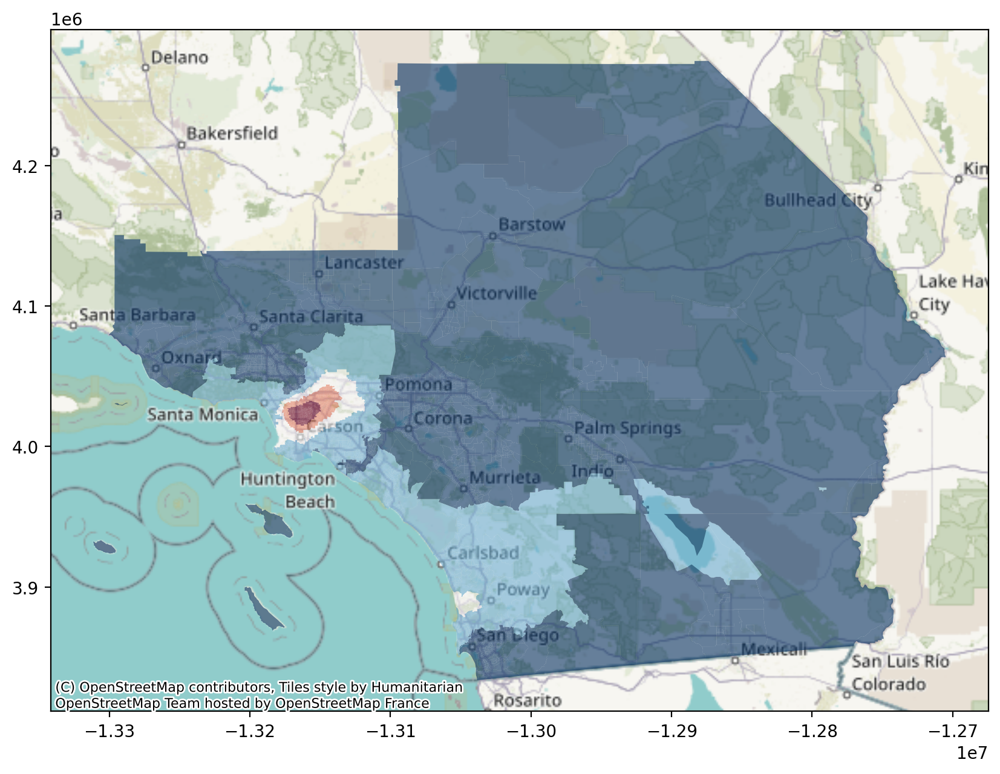

In [88]:
ax = d.data.to_crs(3857).plot(
    "distortion", scheme="fisherjenks", cmap="RdBu_r", alpha=0.6, figsize=(10, 10)
)
ctx.add_basemap(ax=ax)

In [89]:
d.data.explore(
    "distortion",
    cmap="RdBu_r",
    style_kwds={"stroke": False},
    scheme="fisherjenks",
    tiles="Esri.WorldGrayCanvas",
)

## Single-Value Inference

This shows that segregation in the coastal region is considerably larger than the inland region at every scale, though have similar shapes to their overall segregation profiles.

In [90]:
from segregation.inference import SingleValueTest

In [91]:
entropy_test = SingleValueTest(entropy_black)

  0%|          | 0/500 [00:00<?, ?it/s]

In [92]:
entropy_test.p_value

0.0

In [ ]:
entropy_test.plot()

## Comparative Inference

In [93]:
from segregation.inference import TwoValueTest

In [94]:
info_test = TwoValueTest(
    MultiInfoTheory(coastal, pop_groups), 
    
    MultiInfoTheory(inland, pop_groups)
)

  0%|          | 0/500 [00:00<?, ?it/s]

In [96]:
info_test.est_point_diff

0.1212617149430146

OptionError: No such keys(s): 'mode.use_inf_as_null'

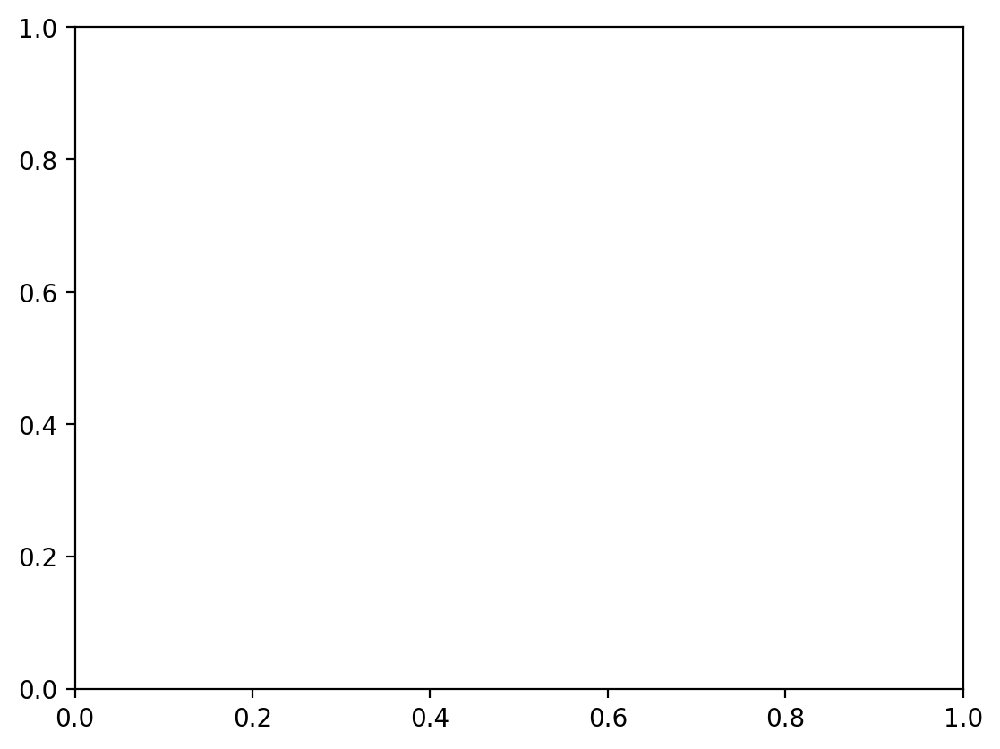

In [97]:
info_test.plot()

## Exercise

1. Which county in the socal region has the greatest level of multiracial segregation, (using the 4 categories above) according to the multigroup Information Theory index?

2. According to the Gini index, is hispanic/latino segregation in Riverside County greater or less than Ventura County? Is that difference significant?


In [ ]:
# %load solutions/06.py